# TRUSTSR Lab 04 — Final Capstone: Adversarial Observability Stress Test

**Phase:** Lab 04 — Recovery-policy evaluation  
**Status:** Synthetic simulation only | Version 1.0.0

## Why this is the final Lab 04 experiment
Labs 04.01–04.03 explored missing dependency edges, uncertainty-aware quarantine, and noisy observable coverage proxies. This capstone combines two failure modes that may interact:

1. **Structured edge omission:** instead of removing edges uniformly at random, the simulator can preferentially omit edges that lie on paths from compromised sources.
2. **Coverage-signal manipulation:** a synthetic attacker can inflate the observable proxy for selected nodes that are truly contaminated but not reached in the observed graph.

The evaluator retains the hidden graph and true contamination set only to calculate metrics. Policies do not receive ground truth, hidden edges, or attacker-target labels.

## Policies under comparison
- **Observed reachability:** quarantine nodes reachable from known compromised sources in the observed graph.
- **Proxy threshold:** observed reachability plus nodes whose observable proxy is below a threshold.
- **Integrity-gated threshold:** proxy-threshold policy plus quarantine of nodes whose proxy-integrity check is flagged invalid. The integrity flag is an *observable synthetic input*, not an oracle label for contamination.
- **Full quarantine:** quarantine every node as a safety-first reference.

The synthetic integrity checker flags a manipulated proxy only when the manipulation is detected under the configured detection probability. Missed manipulations remain possible.

## Research questions
- How much worse can structured edge omission be than random omission?
- Can proxy manipulation increase false negatives for threshold-based policies?
- Does an integrity-gated policy reduce false negatives in these synthetic conditions, and what is its quarantine cost?
- Are any conclusions robust across the chosen parameter settings?

## Evidence boundary
Every graph, attack, detection outcome, policy result, and plot is synthetic. This lab is a reproducible stress test, not evidence of production effectiveness, formal security, or real-world attacker behavior. Do not report simulated results as real deployment measurements.

## 1. Configuration

In [1]:
import random, sys, platform
from collections import defaultdict, deque
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261014
N_TRIALS = 200
N_NODES = 50
EDGE_PROBABILITY = 0.06
MISSING_EDGE_RATE = 0.25
ATTACK_MODES = ["random_omission", "path_targeted_omission"]
PROXY_NOISE = 0.15
PROXY_THRESHOLD = 0.50
PROXY_MANIPULATION_RATE = 0.60
INTEGRITY_DETECTION_PROBABILITY = 0.70
N_COMPROMISED_SOURCES = 2

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation only")
print({
    "seed": SEED, "trials_per_condition": N_TRIALS, "nodes": N_NODES,
    "missing_edge_rate": MISSING_EDGE_RATE, "attack_modes": ATTACK_MODES,
    "proxy_noise": PROXY_NOISE, "proxy_threshold": PROXY_THRESHOLD,
    "proxy_manipulation_rate": PROXY_MANIPULATION_RATE,
    "integrity_detection_probability": INTEGRITY_DETECTION_PROBABILITY
})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:27:02.216980+00:00
Evidence classification: synthetic simulation only
{'seed': 20261014, 'trials_per_condition': 200, 'nodes': 50, 'missing_edge_rate': 0.25, 'attack_modes': ['random_omission', 'path_targeted_omission'], 'proxy_noise': 0.15, 'proxy_threshold': 0.5, 'proxy_manipulation_rate': 0.6, 'integrity_detection_probability': 0.7}


## 2. Graph and attack-simulation helpers

In [2]:
def make_dag(rng, n_nodes, edge_probability):
    nodes = [f"S{i:02d}" for i in range(n_nodes)]
    edges = [(nodes[i], nodes[j]) for i in range(n_nodes) for j in range(i + 1, n_nodes)
             if rng.random() < edge_probability]
    return nodes, edges

def reachable(nodes, edges, sources):
    adj = defaultdict(list)
    for u, v in edges:
        adj[u].append(v)
    seen, queue = set(sources), deque(sources)
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                queue.append(v)
    return seen

def get_path_edges(nodes, edges, sources, target_set):
    # Return edges that participate in at least one source-to-target path.
    # For this DAG, an edge (u,v) is selected when u is source-reachable and
    # v can reach a target. Reverse reachability is computed over reversed edges.
    forward = reachable(nodes, edges, sources)
    reverse_edges = [(v, u) for u, v in edges]
    can_reach_target = reachable(nodes, reverse_edges, target_set)
    return [(u, v) for u, v in edges if u in forward and v in can_reach_target]

def omit_edges(rng, nodes, true_edges, sources, truth, rate, mode):
    n_remove = round(len(true_edges) * rate)
    if mode == "random_omission":
        candidates = list(true_edges)
        rng.shuffle(candidates)
        removed = set(candidates[:n_remove])
    elif mode == "path_targeted_omission":
        candidates = get_path_edges(nodes, true_edges, sources, truth)
        rng.shuffle(candidates)
        removed = set(candidates[:n_remove])
        if len(removed) < n_remove:
            remainder = [e for e in true_edges if e not in removed]
            rng.shuffle(remainder)
            removed.update(remainder[:n_remove - len(removed)])
    else:
        raise ValueError(f"Unknown attack mode: {mode}")
    observed = [e for e in true_edges if e not in removed]
    return observed, list(removed)

def make_proxy(nodes, observed_edges, rng, noise, truth, observed_reachable,
               manipulation_rate, integrity_detection_probability):
    degree = {n: 0 for n in nodes}
    for u, v in observed_edges:
        degree[u] += 1
        degree[v] += 1
    max_degree = max(degree.values()) if degree else 1
    max_degree = max(max_degree, 1)
    raw = {n: degree[n] / max_degree for n in nodes}
    proxy = {n: min(1.0, max(0.0, raw[n] + rng.uniform(-noise, noise))) for n in nodes}

    # Attacker targets truly contaminated nodes that the observed graph does not reach.
    eligible = sorted(set(truth) - set(observed_reachable))
    n_manipulate = min(len(eligible), round(len(eligible) * manipulation_rate))
    targets = set(rng.sample(eligible, n_manipulate)) if n_manipulate else set()
    integrity_invalid = set()
    for node in targets:
        proxy[node] = 1.0  # synthetic signal inflation intended to evade low-proxy quarantine
        if rng.random() < integrity_detection_probability:
            integrity_invalid.add(node)
    return raw, proxy, targets, integrity_invalid

def evaluate(nodes, truth, quarantine):
    truth, quarantine = set(truth), set(quarantine)
    clean = set(nodes) - truth
    fn = truth - quarantine
    fp = clean & quarantine
    return {
        "truth_contaminated": len(truth),
        "truth_clean": len(clean),
        "quarantined": len(quarantine),
        "false_negatives": len(fn),
        "false_negative_rate": len(fn) / len(truth) if truth else 0.0,
        "false_positives": len(fp),
        "false_positive_rate": len(fp) / len(clean) if clean else 0.0,
        "clean_preservation_rate": len(clean - quarantine) / len(clean) if clean else 0.0,
        "quarantine_blast_radius": len(quarantine) / len(nodes)
    }

print("Helpers defined.")

Helpers defined.


## 3. Run paired trials across omission modes

In [3]:
trial_rows, node_rows = [], []
for mode in ATTACK_MODES:
    for trial in range(N_TRIALS):
        seed = SEED + (100000 if mode == "path_targeted_omission" else 0) + trial
        rng = random.Random(seed)
        nodes, true_edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
        sources = set(rng.sample(nodes[:max(3, N_NODES // 4)], N_COMPROMISED_SOURCES))
        truth = reachable(nodes, true_edges, sources)
        observed_edges, omitted_edges = omit_edges(
            rng, nodes, true_edges, sources, truth, MISSING_EDGE_RATE, mode
        )
        observed_truth = reachable(nodes, observed_edges, sources)

        proxy_rng = random.Random(seed + 7654321)
        raw_proxy, proxy, manipulated_targets, integrity_invalid = make_proxy(
            nodes, observed_edges, proxy_rng, PROXY_NOISE, truth, observed_truth,
            PROXY_MANIPULATION_RATE, INTEGRITY_DETECTION_PROBABILITY
        )

        base = set(observed_truth)
        threshold_quarantine = base | {n for n in nodes if proxy[n] < PROXY_THRESHOLD}
        integrity_quarantine = threshold_quarantine | integrity_invalid
        policies = {
            "observed_reachability": base,
            "proxy_threshold": threshold_quarantine,
            "integrity_gated_threshold": integrity_quarantine,
            "full_quarantine": set(nodes)
        }

        for policy, quarantine in policies.items():
            row = evaluate(nodes, truth, quarantine)
            trial_rows.append({
                "attack_mode": mode, "trial": trial, "policy": policy,
                "node_count": len(nodes), "true_edge_count": len(true_edges),
                "observed_edge_count": len(observed_edges),
                "omitted_edge_count": len(omitted_edges),
                "true_contaminated_count": len(truth),
                "unreached_contaminated_count": len(set(truth) - set(observed_truth)),
                "proxy_manipulation_targets": len(manipulated_targets),
                "integrity_alerts": len(integrity_invalid),
                **row
            })
            for node in nodes:
                if node in observed_truth:
                    label = "confirmed_contaminated_by_observed_reachability"
                elif node in integrity_invalid:
                    label = "integrity_alert_detected"
                elif node in manipulated_targets:
                    label = "proxy_manipulation_not_detected"
                elif node in quarantine:
                    label = "quarantined_by_threshold_or_full_policy"
                else:
                    label = "not_flagged"
                node_rows.append({
                    "attack_mode": mode, "trial": trial, "policy": policy, "node": node,
                    "ground_truth_contaminated": node in truth,
                    "reachable_in_observed_graph": node in observed_truth,
                    "raw_observed_degree_proxy": raw_proxy[node],
                    "proxy_after_noise_or_manipulation": proxy[node],
                    "proxy_manipulated": node in manipulated_targets,
                    "integrity_alert": node in integrity_invalid,
                    "quarantined": node in quarantine,
                    "evaluation_label": label
                })

trial_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
expected_trials = len(ATTACK_MODES) * N_TRIALS * 4
assert len(trial_df) == expected_trials
assert len(node_df) == expected_trials * N_NODES
assert trial_df["false_negative_rate"].between(0, 1).all()
assert trial_df["false_positive_rate"].between(0, 1).all()
assert node_df["proxy_after_noise_or_manipulation"].between(0, 1).all()
assert (trial_df[trial_df["policy"] == "full_quarantine"]["false_negatives"] == 0).all()
print("Trial-policy evaluations:", len(trial_df))
print("Node-policy classifications:", len(node_df))
print("Structure, range, and full-quarantine assertions passed.")
display(trial_df.head())

Trial-policy evaluations: 1600
Node-policy classifications: 80000
Structure, range, and full-quarantine assertions passed.


       attack_mode  trial                     policy  node_count  true_edge_count  observed_edge_count  omitted_edge_count  true_contaminated_count  unreached_contaminated_count  \
0  random_omission      0      observed_reachability          50               91                   68                  23                       16                             1   
1  random_omission      0            proxy_threshold          50               91                   68                  23                       16                             1   
2  random_omission      0  integrity_gated_threshold          50               91                   68                  23                       16                             1   
3  random_omission      0            full_quarantine          50               91                   68                  23                       16                             1   
4  random_omission      1      observed_reachability          50               85              

## 4. Aggregate results and check invariants

In [4]:
METRICS = ["false_negative_rate", "false_positive_rate", "clean_preservation_rate",
           "quarantine_blast_radius", "false_negatives", "false_positives", "quarantined"]
summary_df = trial_df.groupby(["attack_mode", "policy"])[METRICS].agg(["mean", "std"]).reset_index()
summary_df.columns = [
    "_".join(str(x) for x in col if str(x) != "").rstrip("_")
    if isinstance(col, tuple) else col for col in summary_df.columns
]
display(summary_df)

for (mode, trial), sub in trial_df.groupby(["attack_mode", "trial"]):
    q = sub.set_index("policy")["quarantined"]
    assert q["integrity_gated_threshold"] >= q["proxy_threshold"]
    assert q["proxy_threshold"] >= q["observed_reachability"]
    assert q["full_quarantine"] == N_NODES
print("Policy-set inclusion assertions passed: integrity-gated ⊇ threshold ⊇ observed reachability.")

              attack_mode                     policy  false_negative_rate_mean  false_negative_rate_std  false_positive_rate_mean  false_positive_rate_std  clean_preservation_rate_mean  \
0  path_targeted_omission            full_quarantine                  0.000000                 0.000000                  1.000000                 0.000000                      0.000000   
1  path_targeted_omission  integrity_gated_threshold                  0.195997                 0.100064                  0.655706                 0.112323                      0.344294   
2  path_targeted_omission      observed_reachability                  0.785602                 0.123710                  0.000000                 0.000000                      1.000000   
3  path_targeted_omission            proxy_threshold                  0.525455                 0.094412                  0.655706                 0.112323                      0.344294   
4         random_omission            full_quarantine        

Policy-set inclusion assertions passed: integrity-gated ⊇ threshold ⊇ observed reachability.


## 5. Plot measured synthetic trade-offs

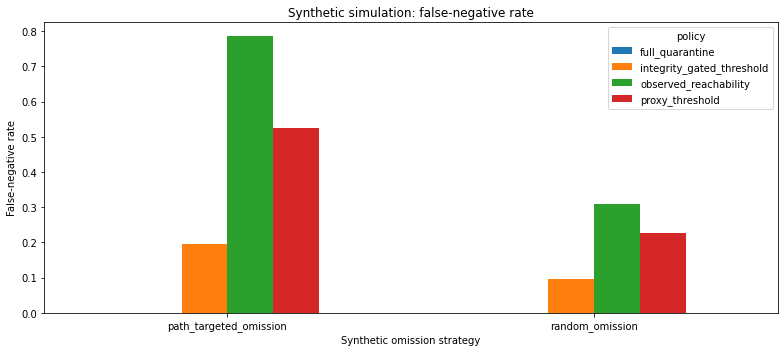

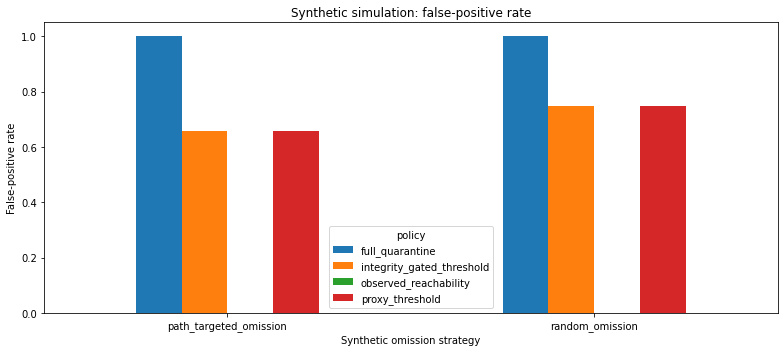

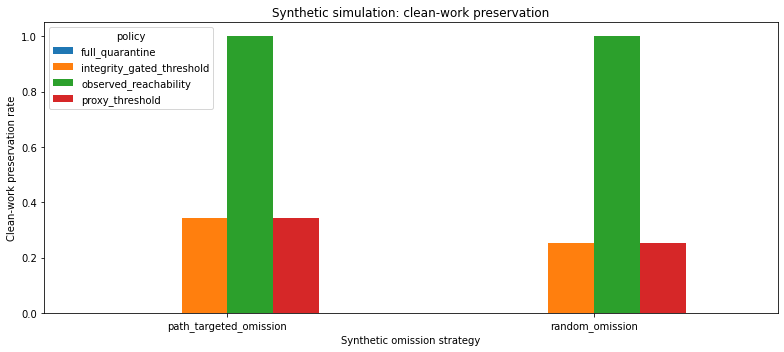

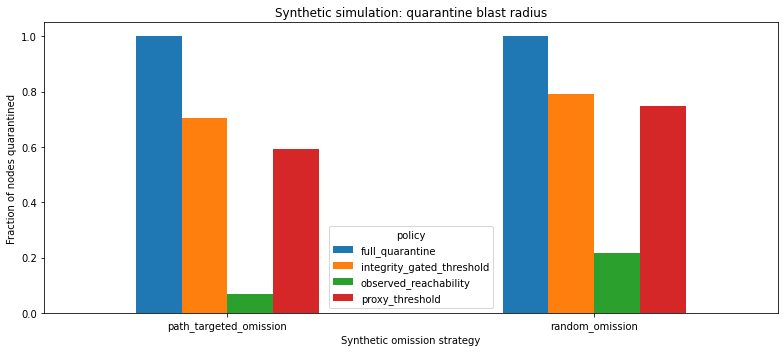

In [5]:
plot_metrics = [
    ("false_negative_rate", "Synthetic simulation: false-negative rate", "False-negative rate"),
    ("false_positive_rate", "Synthetic simulation: false-positive rate", "False-positive rate"),
    ("clean_preservation_rate", "Synthetic simulation: clean-work preservation", "Clean-work preservation rate"),
    ("quarantine_blast_radius", "Synthetic simulation: quarantine blast radius", "Fraction of nodes quarantined")
]
for metric, title, ylabel in plot_metrics:
    pivot = trial_df.groupby(["attack_mode", "policy"])[metric].mean().unstack("policy")
    ax = pivot.plot(kind="bar", figsize=(11, 5))
    ax.set_title(title)
    ax.set_xlabel("Synthetic omission strategy")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 6. Analyze evasion and policy deltas

In [6]:
means = trial_df.groupby(["attack_mode", "policy"])[
    ["false_negative_rate", "false_positive_rate", "clean_preservation_rate",
     "quarantine_blast_radius"]
].mean().reset_index()
display(means)

for mode in ATTACK_MODES:
    sub = means[means["attack_mode"] == mode].set_index("policy")
    print(f"\nOmission mode: {mode}")
    for policy in ["observed_reachability", "proxy_threshold", "integrity_gated_threshold", "full_quarantine"]:
        r = sub.loc[policy]
        print(f"  {policy}: FN={r['false_negative_rate']:.3f}, "
              f"FP={r['false_positive_rate']:.3f}, "
              f"clean_preservation={r['clean_preservation_rate']:.3f}, "
              f"blast_radius={r['quarantine_blast_radius']:.3f}")
    delta_fn = (sub.loc["proxy_threshold", "false_negative_rate"] -
                sub.loc["integrity_gated_threshold", "false_negative_rate"])
    delta_blast = (sub.loc["integrity_gated_threshold", "quarantine_blast_radius"] -
                   sub.loc["proxy_threshold", "quarantine_blast_radius"])
    print(f"  Measured integrity-gate delta: FN reduction={delta_fn:.3f}; "
          f"blast-radius increase={delta_blast:.3f}")

print("\nInterpret only these measured synthetic outputs. A policy is not declared superior by design.")

              attack_mode                     policy  false_negative_rate  false_positive_rate  clean_preservation_rate  quarantine_blast_radius
0  path_targeted_omission            full_quarantine             0.000000             1.000000                 0.000000                   1.0000
1  path_targeted_omission  integrity_gated_threshold             0.195997             0.655706                 0.344294                   0.7043
2  path_targeted_omission      observed_reachability             0.785602             0.000000                 1.000000                   0.0696
3  path_targeted_omission            proxy_threshold             0.525455             0.655706                 0.344294                   0.5924
4         random_omission            full_quarantine             0.000000             1.000000                 0.000000                   1.0000
5         random_omission  integrity_gated_threshold             0.096524             0.747133                 0.252867           


Omission mode: random_omission
  observed_reachability: FN=0.308, FP=0.000, clean_preservation=1.000, blast_radius=0.217
  proxy_threshold: FN=0.226, FP=0.747, clean_preservation=0.253, blast_radius=0.749
  integrity_gated_threshold: FN=0.097, FP=0.747, clean_preservation=0.253, blast_radius=0.791
  full_quarantine: FN=0.000, FP=1.000, clean_preservation=0.000, blast_radius=1.000
  Measured integrity-gate delta: FN reduction=0.129; blast-radius increase=0.042

Omission mode: path_targeted_omission
  observed_reachability: FN=0.786, FP=0.000, clean_preservation=1.000, blast_radius=0.070
  proxy_threshold: FN=0.525, FP=0.656, clean_preservation=0.344, blast_radius=0.592
  integrity_gated_threshold: FN=0.196, FP=0.656, clean_preservation=0.344, blast_radius=0.704
  full_quarantine: FN=0.000, FP=1.000, clean_preservation=0.000, blast_radius=1.000
  Measured integrity-gate delta: FN reduction=0.329; blast-radius increase=0.112

Interpret only these measured synthetic outputs. A policy is n

## 7. Export reproducibility artifacts

In [7]:
trial_df.to_csv("trustsr_lab04_final_trial_results.csv", index=False)
node_df.to_csv("trustsr_lab04_final_node_results.csv", index=False)
summary_df.to_csv("trustsr_lab04_final_summary_mean_std.csv", index=False)
means.to_csv("trustsr_lab04_final_policy_means.csv", index=False)

print("CSV exports created:")
for filename in [
    "trustsr_lab04_final_trial_results.csv",
    "trustsr_lab04_final_node_results.csv",
    "trustsr_lab04_final_summary_mean_std.csv",
    "trustsr_lab04_final_policy_means.csv"
]:
    print("-", filename)
print("Evidence classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab04_final_trial_results.csv
- trustsr_lab04_final_node_results.csv
- trustsr_lab04_final_summary_mean_std.csv
- trustsr_lab04_final_policy_means.csv
Evidence classification: synthetic simulation only.


## 8. Interpretation, limitations, and Lab 04 exit criteria

### Interpret carefully
- Path-targeted omission is a specific synthetic adversary, not a universal model of missing telemetry.
- Proxy manipulation targets contaminated nodes that are not reachable in the observed graph; the evaluator's target selection is hidden from policies.
- The integrity-gated policy sees only synthetic integrity alerts. It does not see which nodes are contaminated.
- Integrity detection is imperfect by design; undetected manipulation can still evade threshold quarantine.
- Full quarantine provides a zero-false-negative reference here by definition, at the cost of quarantining all clean nodes.
- This experiment does not implement actual memory poisoning, agent runtime recovery, cryptographic telemetry attestation, or real attacker behavior.

### Suggested publication wording
“We conducted a controlled synthetic stress test of dependency-edge omission and observable-proxy manipulation. We compared observed reachability, proxy-threshold quarantine, an integrity-gated variant, and full quarantine using false-negative rate, false-positive rate, clean-work preservation, and quarantine blast radius. Results are conditional on the specified simulator and attack assumptions; they do not establish production security or general superiority.”

### Lab 04 is complete when
1. Run all cells in a fresh Colab runtime.
2. Confirm all assertions pass.
3. Inspect the four policy-trade-off plots.
4. Save all four CSV exports.
5. Upload the executed notebook/PDF so the measured outcomes can be reviewed before starting Lab 05.